### Just run it. Script will automatically download the dataset from Hugging face.

**How to run**
- Open this notebook in **Google Colab**.
- Runtime → Change runtime type → **GPU** (optional, speeds up the LSTM).
- Run cells top to bottom (`Runtime → Run all`). No manual upload is needed — the
  dataset is pulled automatically from the Hugging Face Hub.


In [1]:
# Install/upgrade the libraries
!pip install -q datasets scikit-learn tensorflow matplotlib seaborn pandas


In [2]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, auc, classification_report
)

import tensorflow as tf
from keras.models import Sequential
from keras.layers import LSTM, Dense, Dropout, Masking
from keras.callbacks import EarlyStopping

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
sns.set_style("whitegrid")


In [3]:
# Load the dataset from the Hugging Face Hub
raw = load_dataset("bvk/CIC-MalMem-2022")
df = raw["train"].to_pandas()

print("Shape:", df.shape)
print(df.columns.tolist())
df.head()


README.md:   0%|          | 0.00/1.31k [00:00<?, ?B/s]

MalMem2022.csv: reconstructing file:   0%|          |  0.00B / 19.6MB            

MalMem2022.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/58596 [00:00<?, ? examples/s]

Shape: (58596, 58)
['pslist.nproc', 'pslist.nppid', 'pslist.avg_threads', 'pslist.nprocs64bit', 'pslist.avg_handlers', 'dlllist.ndlls', 'dlllist.avg_dlls_per_proc', 'handles.nhandles', 'handles.avg_handles_per_proc', 'handles.nport', 'handles.nfile', 'handles.nevent', 'handles.ndesktop', 'handles.nkey', 'handles.nthread', 'handles.ndirectory', 'handles.nsemaphore', 'handles.ntimer', 'handles.nsection', 'handles.nmutant', 'ldrmodules.not_in_load', 'ldrmodules.not_in_init', 'ldrmodules.not_in_mem', 'ldrmodules.not_in_load_avg', 'ldrmodules.not_in_init_avg', 'ldrmodules.not_in_mem_avg', 'malfind.ninjections', 'malfind.commitCharge', 'malfind.protection', 'malfind.uniqueInjections', 'psxview.not_in_pslist', 'psxview.not_in_eprocess_pool', 'psxview.not_in_ethread_pool', 'psxview.not_in_pspcid_list', 'psxview.not_in_csrss_handles', 'psxview.not_in_session', 'psxview.not_in_deskthrd', 'psxview.not_in_pslist_false_avg', 'psxview.not_in_eprocess_pool_false_avg', 'psxview.not_in_ethread_pool_fal

,pslist.nproc,pslist.nppid,pslist.avg_threads,pslist.nprocs64bit,pslist.avg_handlers,dlllist.ndlls,dlllist.avg_dlls_per_proc,handles.nhandles,handles.avg_handles_per_proc,handles.nport,...,svcscan.process_services,svcscan.shared_process_services,svcscan.interactive_process_services,svcscan.nactive,callbacks.ncallbacks,callbacks.nanonymous,callbacks.ngeneric,Class,Category,Filename
0,45,17,10.555556,0,202.844444,1694,38.500000,9129,212.302326,0,...,24,116,0,121,87,0,8,Benign,Benign,Benign
1,47,19,11.531915,0,242.234043,2074,44.127660,11385,242.234043,0,...,24,118,0,122,87,0,8,Benign,Benign,Benign
2,40,14,14.725000,0,288.225000,1932,48.300000,11529,288.225000,0,...,27,118,0,120,88,0,8,Benign,Benign,Benign
3,32,13,13.500000,0,264.281250,1445,45.156250,8457,264.281250,0,...,27,118,0,120,88,0,8,Benign,Benign,Benign
4,42,16,11.452381,0,281.333333,2067,49.214286,11816,281.333333,0,...,24,118,0,124,87,0,8,Benign,Benign,Benign


In [4]:
# Identify the category column and keep only Benign + Ransomware-* rows
# (CIC-MalMem-2022 encodes the fine-grained label as e.g. "Ransomware-Conti",
#  "Spyware-Gator", "Trojan-Zeus", or "Benign" in a "Category" column.)
category_col = "Category" if "Category" in df.columns else [
    c for c in df.columns if df[c].astype(str).str.contains("Ransomware", case=False).any()
][0]

print(f"Using '{category_col}' as the category column.")
print(df[category_col].apply(lambda x: str(x).split("-")[0]).value_counts())

mask = df[category_col].astype(str).str.contains("Benign", case=False) | \
       df[category_col].astype(str).str.contains("Ransomware", case=False)
ransom_df = df[mask].copy().reset_index(drop=True)

ransom_df["label"] = (
    ransom_df[category_col].astype(str).str.contains("Ransomware", case=False)
).astype(int)

print(f"\nFiltered dataset: {len(ransom_df)} rows "
      f"({(ransom_df['label']==0).sum()} Benign, {(ransom_df['label']==1).sum()} Ransomware)")


Using 'Category' as the category column.
Category
Benign        29298
Spyware       10020
Ransomware     9791
Trojan         9487
Name: count, dtype: int64

Filtered dataset: 39089 rows (29298 Benign, 9791 Ransomware)


/tmp/ipykernel_1792/3812652491.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=ransom_df["label"].map({0: "Benign", 1: "Ransomware"}), palette="Set2")


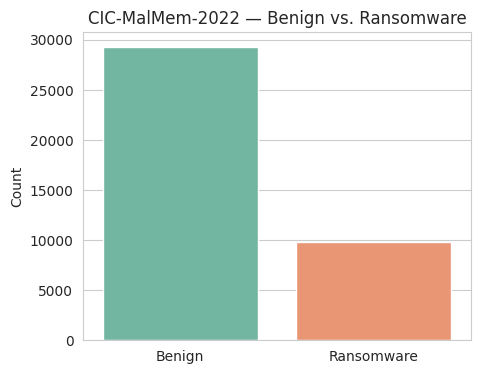

In [5]:
# Class balance with visualisation
plt.figure(figsize=(5, 4))
sns.countplot(x=ransom_df["label"].map({0: "Benign", 1: "Ransomware"}), palette="Set2")
plt.title("CIC-MalMem-2022 — Benign vs. Ransomware")
plt.xlabel("")
plt.ylabel("Count")
plt.show()


In [6]:
# Build the feature matrix
drop_cols = [c for c in ransom_df.columns if ransom_df[c].dtype == object] + ["label"]
feature_cols = [c for c in ransom_df.columns if c not in drop_cols]

# Drop constant (zero-variance) columns
variances = ransom_df[feature_cols].var()
constant_cols = variances[variances == 0].index.tolist()
feature_cols = [c for c in feature_cols if c not in constant_cols]
print(f"Dropped {len(constant_cols)} constant feature(s): {constant_cols}")
print(f"Using {len(feature_cols)} numeric features.")

X = ransom_df[feature_cols].values
y = ransom_df["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train_scaled.shape, " Test:", X_test_scaled.shape)


Dropped 3 constant feature(s): ['pslist.nprocs64bit', 'handles.nport', 'svcscan.interactive_process_services']
Using 52 numeric features.
Train: (31271, 52)  Test: (7818, 52)


In [7]:
# Train a Gradient Boosting classifier
gb_model = HistGradientBoostingClassifier(random_state=SEED, max_iter=200)
gb_model.fit(X_train_scaled, y_train)

gb_preds = gb_model.predict(X_test_scaled)
gb_probs = gb_model.predict_proba(X_test_scaled)[:, 1]

gb_metrics = {
    "Accuracy": accuracy_score(y_test, gb_preds),
    "Precision": precision_score(y_test, gb_preds),
    "Recall": recall_score(y_test, gb_preds),
    "F1-score": f1_score(y_test, gb_preds),
}
print("Gradient Boosting performance:")
for k, v in gb_metrics.items():
    print(f"  {k}: {v:.4f}")
print()
print(classification_report(y_test, gb_preds, target_names=["Benign", "Ransomware"]))


Gradient Boosting performance:
  Accuracy: 1.0000
  Precision: 1.0000
  Recall: 1.0000
  F1-score: 1.0000

              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5860
  Ransomware       1.00      1.00      1.00      1958

    accuracy                           1.00      7818
   macro avg       1.00      1.00      1.00      7818
weighted avg       1.00      1.00      1.00      7818



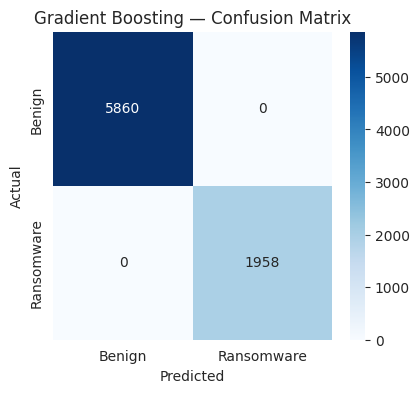

In [8]:
# Gradient Boosting - Confusion Matrix
cm_gb = confusion_matrix(y_test, gb_preds)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm_gb, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Benign", "Ransomware"], yticklabels=["Benign", "Ransomware"])
plt.title("Gradient Boosting — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [9]:
# Gradient Boosting - Feature importance
importances = pd.Series(gb_model.feature_importances_, index=feature_cols) \
    if hasattr(gb_model, "feature_importances_") else None

if importances is not None:
    top15 = importances.sort_values(ascending=False).head(15)
    plt.figure(figsize=(7, 5))
    top15.plot(kind="barh")
    plt.gca().invert_yaxis()
    plt.title("Gradient Boosting — Top 15 Feature Importances")
    plt.xlabel("Importance")
    plt.show()
else:
    print("HistGradientBoostingClassifier does not expose feature_importances_ directly; "
          "use sklearn.inspection.permutation_importance for a model-agnostic alternative.")


HistGradientBoostingClassifier does not expose feature_importances_ directly; use sklearn.inspection.permutation_importance for a model-agnostic alternative.


In [10]:
# Reshape the feature vector into a pseudo-sequence for the LSTM: (timesteps, 1)
n_features = X_train_scaled.shape[1]
X_train_lstm = X_train_scaled.reshape((X_train_scaled.shape[0], n_features, 1))
X_test_lstm = X_test_scaled.reshape((X_test_scaled.shape[0], n_features, 1))

print("LSTM input shape:", X_train_lstm.shape)


LSTM input shape: (31271, 52, 1)


In [11]:
# Build the LSTM model
lstm_model = Sequential([
    Masking(mask_value=0.0, input_shape=(n_features, 1)),
    LSTM(64, return_sequences=True, dropout=0.2),
    LSTM(32, dropout=0.2),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid"),
])

lstm_model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
lstm_model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/masking.py:48: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ masking (Masking)               │ (None, 52, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 52, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,401 (118.75 KB)

 Trainable params: 30,401 (118.75 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Train the LSTM
# The training model stoped at epoch 5 to prevent overfitting because of validation lost did not
# improve fro 3 consecutive epochs (monitor='val_loss' and patience=3.).
early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = lstm_model.fit(
    X_train_lstm, y_train,
    validation_split=0.1,
    epochs=20,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1,
)


Epoch 1/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9239 - loss: 0.2368 - val_accuracy: 0.9926 - val_loss: 0.0282
Epoch 2/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9482 - loss: 0.1264 - val_accuracy: 0.9984 - val_loss: 0.0040
Epoch 3/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9502 - loss: 0.1374 - val_accuracy: 0.9866 - val_loss: 0.0410
Epoch 4/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9488 - loss: 0.1205 - val_accuracy: 0.9946 - val_loss: 0.0176
Epoch 5/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9505 - loss: 0.1150 - val_accuracy: 0.9930 - val_loss: 0.0245


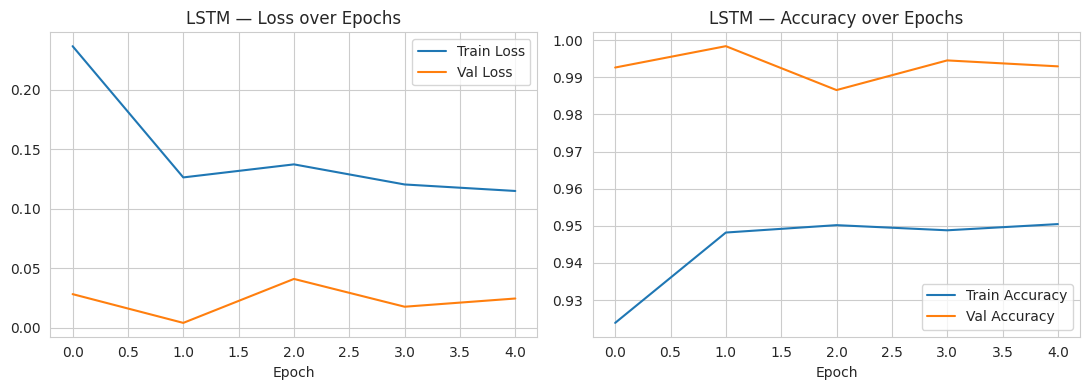

In [13]:
# Training curves with visualisation
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("LSTM — Loss over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Train Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Val Accuracy")
axes[1].set_title("LSTM — Accuracy over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()


In [14]:
# Evaluate the LSTM on the held-out test set
lstm_probs = lstm_model.predict(X_test_lstm).ravel()
lstm_preds = (lstm_probs >= 0.5).astype(int)

lstm_metrics = {
    "Accuracy": accuracy_score(y_test, lstm_preds),
    "Precision": precision_score(y_test, lstm_preds),
    "Recall": recall_score(y_test, lstm_preds),
    "F1-score": f1_score(y_test, lstm_preds),
}
print("LSTM performance:")
for k, v in lstm_metrics.items():
    print(f"  {k}: {v:.4f}")
print()
print(classification_report(y_test, lstm_preds, target_names=["Benign", "Ransomware"]))


245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
LSTM performance:
  Accuracy: 0.9988
  Precision: 0.9954
  Recall: 1.0000
  F1-score: 0.9977

              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5860
  Ransomware       1.00      1.00      1.00      1958

    accuracy                           1.00      7818
   macro avg       1.00      1.00      1.00      7818
weighted avg       1.00      1.00      1.00      7818



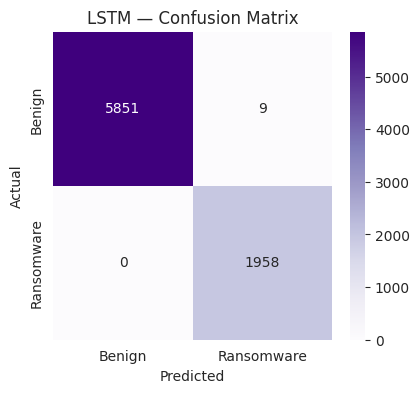

In [15]:
# LSTM - Confusion Matrix
cm_lstm = confusion_matrix(y_test, lstm_preds)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm_lstm, annot=True, fmt="d", cmap="Purples",
            xticklabels=["Benign", "Ransomware"], yticklabels=["Benign", "Ransomware"])
plt.title("LSTM — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


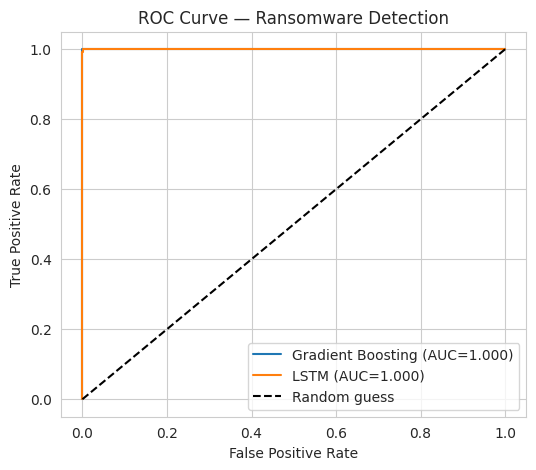

In [16]:
# ROC Curve comparison
fpr_gb, tpr_gb, _ = roc_curve(y_test, gb_probs)
fpr_lstm, tpr_lstm, _ = roc_curve(y_test, lstm_probs)
auc_gb = auc(fpr_gb, tpr_gb)
auc_lstm = auc(fpr_lstm, tpr_lstm)

plt.figure(figsize=(6, 5))
plt.plot(fpr_gb, tpr_gb, label=f"Gradient Boosting (AUC={auc_gb:.3f})")
plt.plot(fpr_lstm, tpr_lstm, label=f"LSTM (AUC={auc_lstm:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Ransomware Detection")
plt.legend(loc="lower right")
plt.show()


                   Accuracy  Precision  Recall  F1-score
Gradient Boosting    1.0000     1.0000     1.0    1.0000
LSTM                 0.9988     0.9954     1.0    0.9977


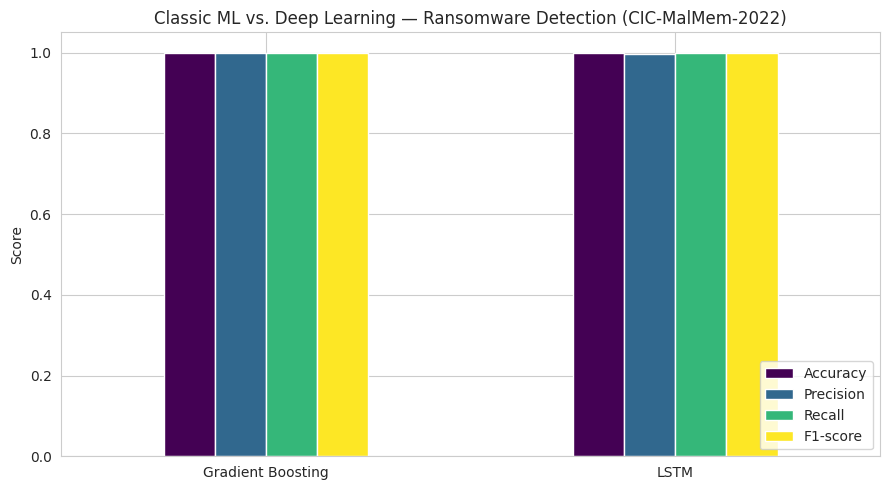

In [17]:
# Side-by-side comparison table and chart
comparison = pd.DataFrame({
    "Gradient Boosting": gb_metrics,
    "LSTM": lstm_metrics,
}).T

print(comparison.round(4))

comparison.plot(kind="bar", figsize=(9, 5), colormap="viridis")
plt.title("Classic ML vs. Deep Learning — Ransomware Detection (CIC-MalMem-2022)")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()
